# Week 2 (companion): Feature Experiments, what the pre-delivery signals can and cannot do

<sub>[Main Week 2 notebook: Feature Engineering and the Leakage Audit](week2_01_features_and_leakage.ipynb) · the tested code is documented in [the project code reference](week1_00_project_code_reference.ipynb)</sub>

The main Week 2 notebook made the leakage argument qualitatively and built the leakage-safe feature matrix. This companion is the empirical lab that JUSTIFIES those choices with numbers. It does two things. First, it demonstrates leakage end to end: a clean pre-delivery model versus a leakage-included one, scored on held-out data, so the gap between honest and fraudulent is a measured quantity, not a warning. Second, it explores the pre-delivery features from every angle I could think of (single-feature strength, in-model importance, linear correlation, nonlinear association, dimensionality, and natural subpopulations) to understand exactly what signal is there.

One scope note up front. This is exploration and justification, not model selection. The calibrated baseline models, the gradient-boosting comparison, and the formal fairness audit are Week 3 and beyond, and everything about them here is written as the PLAN, not as a result already delivered. Nothing in this project is a clinical tool.

### Contents

1. [Setup: load the full-data results, sample a slim frame](#setup)
2. [The dual-track experiment: the leakage lesson, quantified](#dualtrack)
3. [Per-feature contribution: univariate AUC and gain importance](#contribution)
4. [Correlation and mutual information: compare and contrast](#corrmi)
5. [PCA: is the feature space redundant?](#pca)
6. [Clustering: do natural risk subpopulations emerge?](#clusters)
7. [What this means for modeling (PLANNED)](#plan)

<a id="setup"></a>
## Setup: load the full-data results, sample a slim frame

The heavy compute is already done. The dual-track models, the univariate and in-model importance rankings, correlation, mutual information, PCA, and clustering were all computed on the COMPLETE 2018-2024 singleton population by the tested script `scripts/week2_experiments.py`, and serialized to `reports/week2_experiments.json`. We load that JSON here and display it. The only live computation is a few descriptive stats on a slim 300K-row sample, so the notebook stays memory-safe and never retrains anything in a cell.

In [1]:
# This companion is the empirical lab behind Week 2. The heavy numbers (the clean/leakage dual-track
# models, the univariate rank-sum AUCs, the LightGBM gain importance, Pearson correlation, mutual
# information, PCA, and KMeans clustering) were all computed on the COMPLETE 2018-2024 singleton
# population by the tested script scripts/week2_experiments.py and written to
# reports/week2_experiments.json. We LOAD those results here rather than recomputing them, so the
# notebook stays fast and memory-safe. The only things we compute live are cheap descriptive stats on
# a slim sample, so nothing heavy runs in a cell.
#
# Cap Polars threads BEFORE importing it, so a shared kernel does not oversubscribe cores. This mirrors
# the memory care in the sibling notebooks: we never load all ~24.9M rows densely here.
import os
os.environ["POLARS_MAX_THREADS"] = "4"

import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
RNG = 7

# The full-data results, precomputed by the tested experiment script on the complete population.
REPORTS = Path("..") / "reports"
EXP = json.loads((REPORTS / "week2_experiments.json").read_text())

PALETTE = {"blue": "#0072B2", "orange": "#E69F00", "green": "#009E73", "red": "#D55E00",
           "purple": "#CC79A7", "sky": "#56B4E9", "yellow": "#F0E442", "grey": "#999999",
           "ink": "#1a1a2e"}
RACE_ORDER = ["NH White", "NH Asian", "Hispanic", "NH Multiracial", "NH NHOPI", "NH AIAN", "NH Black"]

plt.rcParams.update({"figure.figsize": (8.6, 4.8), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
                     "axes.titlesize": 13, "axes.titleweight": "bold", "font.size": 11,
                     "axes.titlepad": 10, "font.family": "DejaVu Sans"})

def style(ax, title, xlabel, ylabel):
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    return ax


In [2]:
print(f"Full singleton population behind these results: {EXP['n_singletons']:,} births.")
print(f"Dual-track training cap: {EXP['train_rows_used']:,} rows; "
      f"mutual-information subsample: {EXP['mi_subsample_rows']:,} rows.")
print('Sections available in the results file:')
for k in sorted(EXP): print('  -', k)

Full singleton population behind these results: 24,920,407 births.
Dual-track training cap: 5,000,000 rows; mutual-information subsample: 1,000,000 rows.
Sections available in the results file:
  - clusters
  - correlation
  - dual_track
  - gain_importance
  - mi_subsample_rows
  - mutual_info
  - n_singletons
  - pca
  - train_note
  - train_rows_used
  - univariate_auc


Each notebook stands on its own, so here is the slim descriptive sample and a few real rows of the leakage-safe pre-delivery feature matrix. The `split` column marks the deterministic train / validation / test / held-out partitions, so every row is tagged with the fold it belongs to.

In [3]:
# Self-contained: read a SLIM projection of the modeling working set so the notebook stands on its own
# and can show real rows. We take only a handful of columns and sample down, so this stays light; the
# heavy population numbers all come from EXP (the JSON), never from a dense in-notebook computation.
DATA = Path("..") / "data" / "processed" / "modeling_full_2018_2024.parquet"
SAMPLE_COLS = ["preterm", "split", "mother_race_ethnicity", "mager", "meduc", "bmi",
               "medical_risk_count", "rf_ppterm", "first_trimester_care", "married"]

# Sample rather than collect all rows: a fixed-seed 300K slice is plenty for descriptive display and
# keeps the kernel memory-safe. The population-scale figures live in EXP.
mdf = (pl.scan_parquet(DATA)
       .select(SAMPLE_COLS)
       .collect()
       .sample(n=300_000, seed=RNG))
print(f"Slim descriptive sample: {mdf.shape[0]:,} rows x {mdf.shape[1]} columns "
      f"(the heavy numbers below come from the full-data JSON, not from this sample).")


Slim descriptive sample: 300,000 rows x 10 columns (the heavy numbers below come from the full-data JSON, not from this sample).


In [4]:
mdf.sample(5, seed=RNG).to_pandas()

,preterm,split,mother_race_ethnicity,mager,meduc,bmi,medical_risk_count,rf_ppterm,first_trimester_care,married
0,0,dev_test,NH White,32.0,7,27.799999,0,0,1,1.0
1,0,dev_train,NH White,34.0,6,24.700001,1,0,1,NaN
2,0,held_out_final,Hispanic,26.0,4,23.200001,0,0,1,NaN
3,0,held_out_final,Hispanic,35.0,4,30.700001,0,0,1,NaN
4,0,held_out_final,NH White,28.0,3,24.200001,0,0,1,1.0


<a id="dualtrack"></a>
## The dual-track experiment: the leakage lesson, quantified

This is the headline. The main notebook argued that at-delivery fields must be barred because they leak. Here that argument becomes a measurement. Two models were trained: a **clean** track on the leakage-safe pre-delivery matrix only, and a **leakage** track that additionally lets the barred at-delivery fields in. Both were scored on the same untouched held-out partition. If leakage is real, the leakage track should look near-perfect and be worthless, because those fields do not exist at the moment a real prediction would be made.

In [5]:
dt = EXP['dual_track']
clean, leak = dt['clean'], dt['leakage']
print(f"{'track':<28}{'AUC-PR':>10}{'AUC-ROC':>10}")
print(f"{'clean (leakage-safe)':<28}{clean['auc_pr']:>10.4f}{clean['auc_roc']:>10.4f}")
print(f"{'leakage-included':<28}{leak['auc_pr']:>10.4f}{leak['auc_roc']:>10.4f}")
print(f"\nGap (leakage minus clean):  AUC-PR +{leak['auc_pr']-clean['auc_pr']:.4f}, "
      f"AUC-ROC +{leak['auc_roc']-clean['auc_roc']:.4f}")

track                           AUC-PR   AUC-ROC
clean (leakage-safe)            0.1810    0.6590
leakage-included                0.7615    0.9394

Gap (leakage minus clean):  AUC-PR +0.5806, AUC-ROC +0.2804


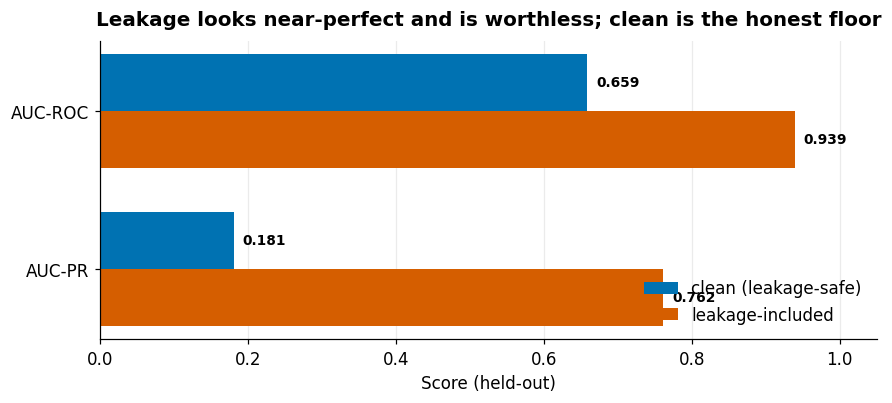

In [6]:
labels = ['AUC-PR', 'AUC-ROC']
clean_v = [clean['auc_pr'], clean['auc_roc']]
leak_v = [leak['auc_pr'], leak['auc_roc']]
y = np.arange(len(labels)); h = 0.36
fig, ax = plt.subplots(figsize=(8.2, 3.8))
b1 = ax.barh(y + h/2, clean_v, height=h, color=PALETTE['blue'], label='clean (leakage-safe)')
b2 = ax.barh(y - h/2, leak_v, height=h, color=PALETTE['red'], label='leakage-included')
for bars, vals in [(b1, clean_v), (b2, leak_v)]:
    for bar, v in zip(bars, vals):
        ax.text(v + 0.012, bar.get_y() + bar.get_height()/2, f'{v:.3f}',
                va='center', fontweight='bold', fontsize=9)
ax.set_yticks(y); ax.set_yticklabels(labels)
style(ax, 'Leakage looks near-perfect and is worthless; clean is the honest floor',
      'Score (held-out)', '')
ax.set_xlim(0, 1.05); ax.grid(axis='y'); ax.legend(frameon=False, loc='lower right')
plt.tight_layout(); plt.show()

In [7]:
print('Compute basis, disclosed verbatim from the results file:')
print(' ', EXP['train_note'])

Compute basis, disclosed verbatim from the results file:
  clean/leakage tracks trained on a stratified cap of 5,000,000 dev_train rows (full dev_train was 10,466,570); held-out scoring used the full held_out_final partition.


**The leakage track reaches AUC-ROC about 0.94 and is worthless.** That near-perfect number is exactly the danger the leakage discipline guards against: it is built partly from fields recorded at or after delivery, which do not exist when a prediction would actually be made, so it is reading the answer off the outcome. The clean track's AUC-ROC around 0.66 is the honest, forward-looking picture: modest, because the legitimate pre-delivery signals are individually weak, and that is the whole point of Week 2.

Two honesty notes. First, the disclosed compute basis above matters: both tracks were trained on a stratified cap of 5,000,000 development-train rows (the full development-train partition was larger), while scoring used the entire held-out partition, so the comparison is fair and the training cap is stated openly. Second, this clean 0.66 is a FLOOR from a single quick-trained comparison model, not the project's final result. Calibrated model selection (logistic regression as the calibration reference, trees, then tuned gradient boosting) is Week 3 and beyond, framed as PLANNED, and nothing here is a clinical tool. What this section delivers is the end-to-end proof of the lesson the main notebook made qualitatively: leakage buys a spectacular, fraudulent number, and the discipline trades it for an honest one.

<a id="contribution"></a>
## Per-feature contribution: univariate AUC and gain importance

If the clean ceiling is modest, the natural next question is which features carry what little signal there is, and I want to see it two ways. **Univariate AUC** (a full-data rank-sum computation) asks how well each feature predicts preterm *on its own*, a marginal view. **LightGBM gain importance** from the clean track asks how much each feature contributed *inside the model*, an interaction-aware view. They answer different questions, so agreement between them is reassuring.

Top 15 features by univariate (single-feature) AUC, full-data rank-sum:
  medical_risk_count                 0.570
  rf_ppterm                          0.544
  bmi                                0.543
  pay_1                              0.536
  mother_race_ethnicity_NH Black     0.533
  rf_cesar                           0.524
  rf_phype                           0.521
  mager                              0.516
  age_bracket                        0.515
  priorlive                          0.514
  cig_0                              0.514
  wic                                0.514
  race_education_NH Black_edu3       0.514
  rf_pdiab                           0.513
  race_education_NH Black_edu4       0.508


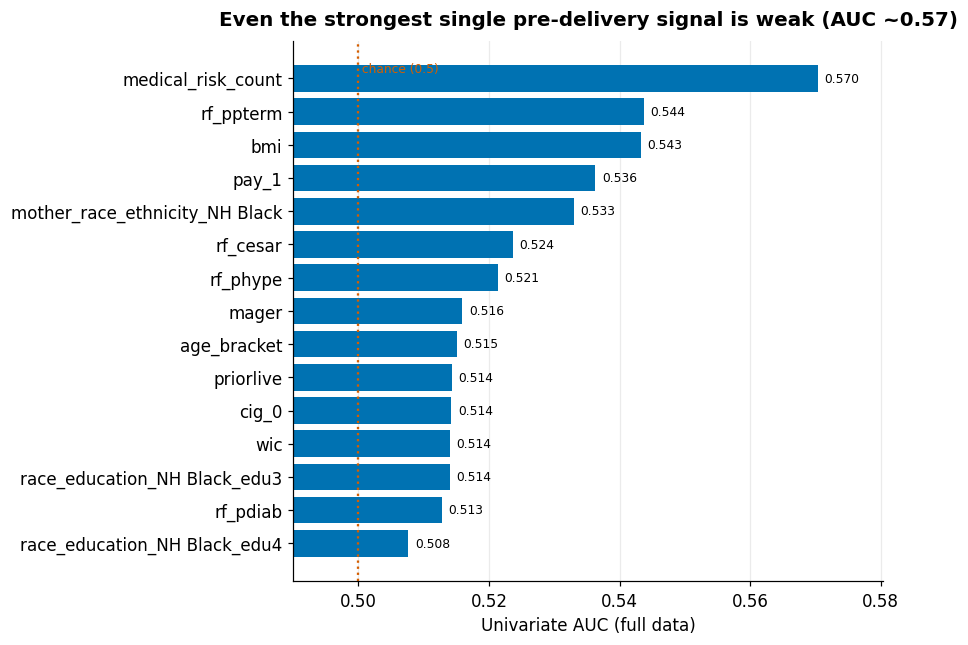

In [8]:
uni = EXP['univariate_auc'][:15]
print('Top 15 features by univariate (single-feature) AUC, full-data rank-sum:')
for r in uni:
    print(f"  {r['feature']:<34} {r['univariate_auc']:.3f}")
feats = [r['feature'] for r in uni][::-1]; vals = [r['univariate_auc'] for r in uni][::-1]
fig, ax = plt.subplots(figsize=(8.4, 6.0))
ax.barh(feats, vals, color=PALETTE['blue'])
for i, v in enumerate(vals): ax.text(v + 0.001, i, f'{v:.3f}', va='center', fontsize=8)
ax.axvline(0.5, ls=':', color=PALETTE['red'])
ax.text(0.5, len(feats)-0.5, ' chance (0.5)', color=PALETTE['red'], fontsize=8, va='top')
style(ax, 'Even the strongest single pre-delivery signal is weak (AUC ~0.57)',
      'Univariate AUC (full data)', ''); ax.grid(axis='y')
ax.set_xlim(0.49, max(vals) + 0.01); plt.tight_layout(); plt.show()

Top 15 features by LightGBM gain importance (clean track), gain shown relative to the max:
  rf_ppterm                          gain      2,088,361  (100.0% of max)
  medical_risk_count                 gain        741,028  ( 35.5% of max)
  bmi                                gain        735,527  ( 35.2% of max)
  priorlive                          gain        605,596  ( 29.0% of max)
  rf_phype                           gain        534,541  ( 25.6% of max)
  mager                              gain        515,648  ( 24.7% of max)
  married                            gain        447,388  ( 21.4% of max)
  meduc                              gain        377,292  ( 18.1% of max)
  first_trimester_care               gain        312,812  ( 15.0% of max)
  rf_pdiab                           gain        291,214  ( 13.9% of max)
  mother_race_ethnicity_NH Black     gain        262,483  ( 12.6% of max)
  cig_0                              gain        174,166  (  8.3% of max)
  mother_race_ethnici

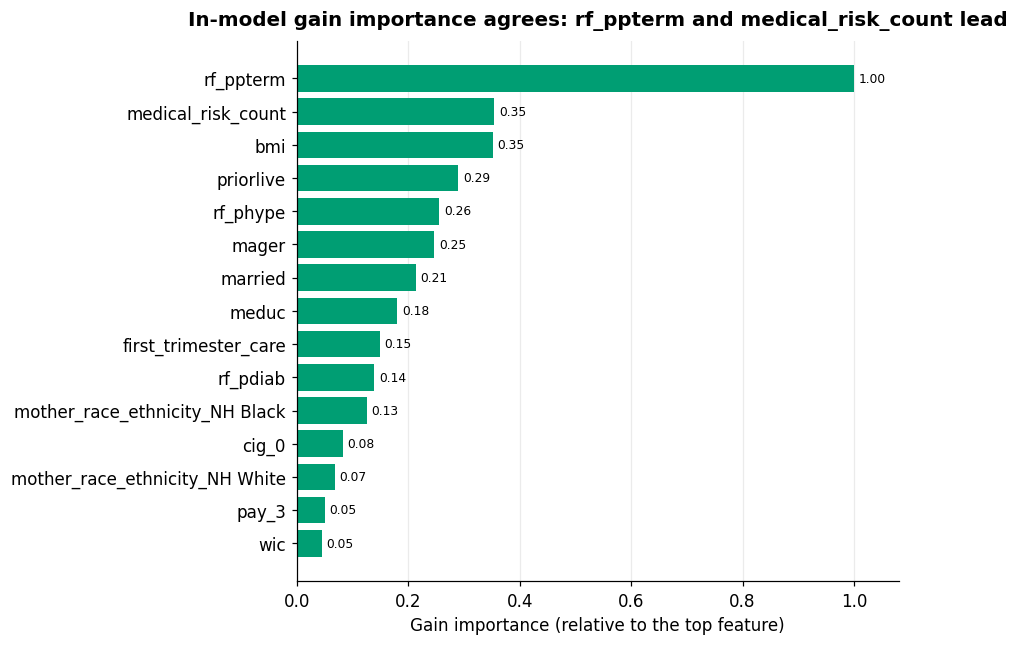

In [9]:
gain = EXP['gain_importance'][:15]
gmax = gain[0]['gain']
print('Top 15 features by LightGBM gain importance (clean track), gain shown relative to the max:')
for r in gain:
    print(f"  {r['feature']:<34} gain {r['gain']:>14,.0f}  ({r['gain']/gmax*100:5.1f}% of max)")
feats = [r['feature'] for r in gain][::-1]; vals = [r['gain']/gmax for r in gain][::-1]
fig, ax = plt.subplots(figsize=(8.4, 6.0))
ax.barh(feats, vals, color=PALETTE['green'])
for i, v in enumerate(vals): ax.text(v + 0.008, i, f'{v:.2f}', va='center', fontsize=8)
style(ax, 'In-model gain importance agrees: rf_ppterm and medical_risk_count lead',
      'Gain importance (relative to the top feature)', ''); ax.grid(axis='y')
ax.set_xlim(0, 1.08); plt.tight_layout(); plt.show()

**The strongest single signal is weak, and the two views agree.** The best univariate feature, the enumerated medical-risk count, reaches only about 0.57 AUC on its own, and prior preterm birth (`rf_ppterm`) is the strongest by in-model gain and, as the next section shows, by linear correlation too. Everything else is close to the 0.5 chance line. That weakness is the honest reason the clean ceiling is modest: there is simply no single pre-delivery field that carries strong predictive power. The reassuring part is that the marginal ranking (univariate AUC) and the in-model ranking (gain) mostly agree, with `rf_ppterm`, `medical_risk_count`, and `bmi` near the top of both. When a purely marginal measure and an interaction-aware one point at the same handful of features, I trust the signal more, even though it is small.

<a id="corrmi"></a>
## Correlation and mutual information: compare and contrast

Two more lenses on the same features, and this is where careful reading matters most. **Pearson correlation** (computed on the full data) measures *linear* association with the outcome. **Mutual information** (estimated on a 1,000,000-row subsample) can additionally pick up *nonlinear or categorical* association that a linear correlation misses. Comparing the two rankings is instructive, but only if we read the mutual-information side honestly.

In [10]:
corr = EXP['correlation'][:12]
print('Top 12 features by |Pearson correlation| with preterm (full data):')
for r in corr:
    print(f"  {r['feature']:<36} {r['corr']:+.3f}")
print(f"\nStrongest linear correlation is only {abs(corr[0]['corr']):.3f} ({corr[0]['feature']}).")

Top 12 features by |Pearson correlation| with preterm (full data):
  rf_ppterm                            +0.130
  medical_risk_count                   +0.117
  rf_phype                             +0.074
  rf_pdiab                             +0.068
  mother_race_ethnicity_NH Black       +0.053
  married                              -0.051
  meduc                                -0.047
  bmi                                  +0.046
  pay_1                                +0.041
  mother_race_ethnicity_NH White       -0.037
  rf_cesar                             +0.037
  pay_2                                -0.036

Strongest linear correlation is only 0.130 (rf_ppterm).


In [11]:
mi = EXP['mutual_info'][:12]
print(f"Top 12 features by mutual information (estimated on {EXP['mi_subsample_rows']:,} rows):")
for r in mi:
    print(f"  {r['feature']:<36} {r['mi']:.4f}")
corr_top = {r['feature'] for r in EXP['correlation'][:5]}
mi_top = {r['feature'] for r in EXP['mutual_info'][:5]}
print('\nTop-5 overlap between the correlation and MI rankings:',
      sorted(corr_top & mi_top) or '(none)')

Top 12 features by mutual information (estimated on 1,000,000 rows):
  first_trimester_care                 0.1651
  married                              0.1528
  mother_race_ethnicity_NH White       0.1223
  pay_2                                0.1222
  pay_1                                0.0852
  wic                                  0.0541
  age_bracket                          0.0449
  mother_race_ethnicity_Hispanic       0.0348
  meduc                                0.0343
  priorlive                            0.0258
  medical_risk_count                   0.0235
  rf_cesar                             0.0135

Top-5 overlap between the correlation and MI rankings: (none)


**The two rankings disagree at the top, and the honest reading is the careful one.** Linear correlation puts `rf_ppterm` and `medical_risk_count` on top, matching the univariate-AUC and gain rankings. Mutual information instead puts `first_trimester_care` and `married` at the top, features that do NOT lead the correlation or the univariate-AUC rankings. It is tempting to read that as *these are secretly strong predictors that linear methods missed*, and I want to resist that.

Descriptively, mutual information can indeed capture nonlinear or categorical association that Pearson correlation cannot, so it is a legitimate different lens. But there is a real caveat: estimating mutual information against a rare binary outcome (about 8.6% prevalence) is noisy, and it can be inflated for low-variance binary features. So the top of the MI ranking should be read as a *hint* about where nonlinear structure might live, not as evidence that `first_trimester_care` is a strong predictor. It is not: its own univariate AUC sits near the chance line with everything else. The honest indicator across all of these lenses is the same one from the previous section: the univariate AUCs, all clustered near the 0.5 chance line (roughly 0.45 to 0.57, with protective-direction features like education and being married landing below 0.5), so no single pre-delivery feature is more than about 0.07 of AUC away from a coin flip. That is what says plainly that no single pre-delivery feature is strongly predictive of preterm birth.

<a id="pca"></a>
## PCA: is the feature space redundant?

A different question: are these weak signals actually redundant, collapsing into a few dominant directions, or is the pre-delivery feature space genuinely spread out? Principal component analysis answers it. If a handful of components captured most of the variance, there would be a low-dimensional shortcut worth exploiting. If not, the coming modeling weeks have to respect the full breadth of the features.

Explained variance by principal component (first 10):
  PC1   4.58%   cumulative  4.58%
  PC2   2.62%   cumulative  7.20%
  PC3   2.37%   cumulative  9.57%
  PC4   2.12%   cumulative 11.69%
  PC5   2.02%   cumulative 13.71%
  PC6   1.95%   cumulative 15.66%
  PC7   1.94%   cumulative 17.60%
  PC8   1.80%   cumulative 19.40%
  PC9   1.66%   cumulative 21.07%
  PC10  0.98%   cumulative 22.05%

Top 10 components together explain 22.05% of the variance.


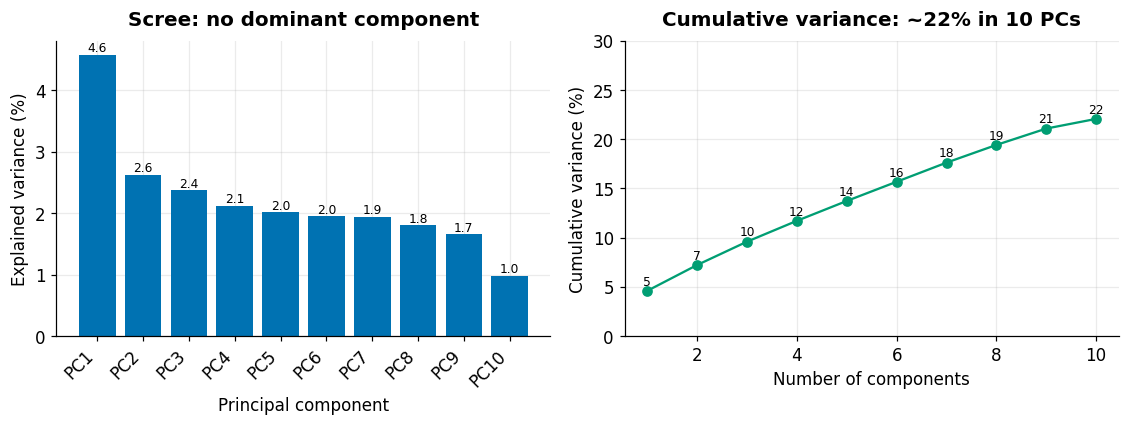

In [12]:
pca = EXP['pca']
evr = pca['explained_variance_ratio']; cum = pca['cumulative']
print('Explained variance by principal component (first 10):')
for i, (e, c) in enumerate(zip(evr, cum), 1):
    print(f"  PC{i:<2} {e*100:5.2f}%   cumulative {c*100:5.2f}%")
print(f"\nTop 10 components together explain {cum[-1]*100:.2f}% of the variance.")
fig, (axL, axR) = plt.subplots(1, 2, figsize=(10.4, 4.0))
pcs = [f'PC{i}' for i in range(1, len(evr)+1)]
axL.bar(pcs, [e*100 for e in evr], color=PALETTE['blue'])
for i, e in enumerate(evr): axL.text(i, e*100 + 0.05, f'{e*100:.1f}', ha='center', fontsize=8)
style(axL, 'Scree: no dominant component', 'Principal component', 'Explained variance (%)')
plt.setp(axL.get_xticklabels(), rotation=45, ha='right')
axR.plot(range(1, len(cum)+1), [c*100 for c in cum], marker='o', color=PALETTE['green'])
for i, c in enumerate(cum, 1): axR.text(i, c*100 + 0.6, f'{c*100:.0f}', ha='center', fontsize=8)
style(axR, 'Cumulative variance: ~22% in 10 PCs', 'Number of components', 'Cumulative variance (%)')
axR.set_ylim(0, max(30, cum[-1]*100 + 6)); plt.tight_layout(); plt.show()

In [13]:
print('Top-8 loadings for the first three components (which raw features each PC weights most):')
for pc in ['PC1', 'PC2', 'PC3']:
    print(f"\n{pc}:")
    for r in pca['loadings'][pc]:
        print(f"  {r['feature']:<34} {r['loading']:+.3f}")

Top-8 loadings for the first three components (which raw features each PC weights most):

PC1:
  meduc                              +0.366
  pay_2                              +0.352
  pay_1                              -0.346
  wic                                -0.285
  married                            +0.262
  mager                              +0.260
  age_bracket                        +0.256
  mother_race_ethnicity_NH White     +0.239

PC2:
  medical_risk_count                 +0.399
  mager                              +0.363
  age_bracket                        +0.360
  rf_cesar                           +0.338
  priorlive                          +0.301
  mother_race_ethnicity_NH White     -0.295
  rf_ppterm                          +0.198
  race_education_NH White_edu3       -0.166

PC3:
  mother_race_ethnicity_Hispanic     +0.406
  mother_race_ethnicity_NH White     -0.349
  mother_race_ethnicity_NH Asian     +0.277
  medical_risk_count                 -0.270
  race_educat

**The feature space is largely non-redundant.** The strongest single component (PC1) explains only about 4.6% of the variance, and the first 10 components together reach only about 22%. Reaching 80% or 90% of the variance would take far more than 10 components. In other words, the weak signals do not collapse into a few dominant directions; they are spread thin across many, so there is no low-dimensional shortcut to exploit, and the coming modeling weeks have to work with the features roughly as they are. One piece of context, not a defect: the matrix is one-hot-heavy (race, payment source, and marital status are each expanded into indicator columns), and a one-hot-heavy design of this width inflates the raw dimensionality, which is part of why the variance looks so spread out.

<a id="clusters"></a>
## Clustering: do natural risk subpopulations emerge?

The last lens is unsupervised. KMeans was run on the full population to ask whether natural subpopulations fall out of the pre-delivery features, and if so, how their preterm rates spread around the 8.6% base rate. This is strictly a descriptive, associational look at structure in the data, not a risk-scoring tool.

In [14]:
clusters = sorted(EXP['clusters'], key=lambda c: c['cluster'])
print(f"{'cluster':>7}{'size':>13}{'preterm':>10}   top races (share)          key feature means")
for c in clusters:
    races = ', '.join(f"{m['race']} {m['share']*100:.0f}%" for m in c['race_mix'])
    fm = c['feature_means']
    means = ', '.join(f"{k}={v:.2f}" for k, v in fm.items())
    print(f"{c['cluster']:>7}{c['size']:>13,}{c['preterm_rate']*100:>9.1f}%   {races:<26} {means}")

cluster         size   preterm   top races (share)          key feature means
      0   11,994,818      9.9%   Hispanic 39%, NH White 32%, NH Black 23% mager=26.70, bmi=30.38, medical_risk_count=0.25
      1    8,804,796      7.7%   NH White 58%, Hispanic 16%, NH Asian 14% mager=32.03, bmi=28.16, medical_risk_count=0.22
      2      196,073      8.7%   NH White 41%, Hispanic 35%, NH Black 13% mager=28.60, bmi=29.60, medical_risk_count=0.24
      3      317,500      9.1%   NH White 46%, Hispanic 31%, NH Black 13% mager=28.91, bmi=29.02, medical_risk_count=0.23
      4      175,646      8.5%   NH Asian 100%              mager=30.06, bmi=26.55, medical_risk_count=0.23
      5    3,431,574      6.1%   NH White 100%              mager=31.56, bmi=27.28, medical_risk_count=0.19


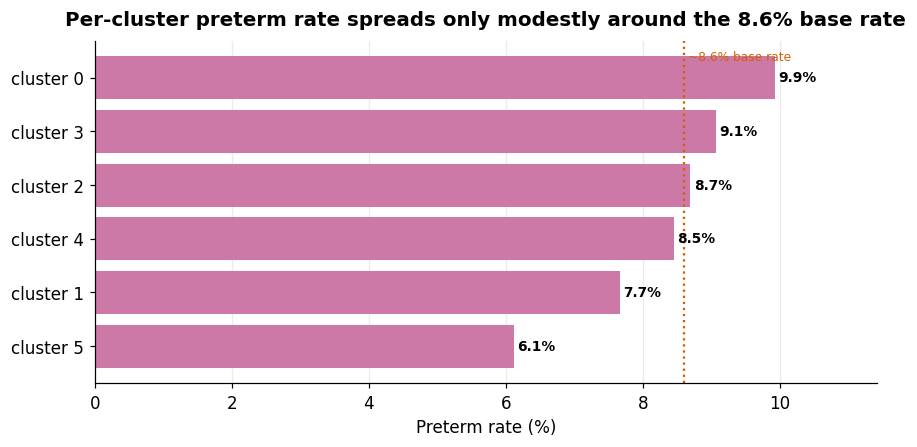

In [15]:
base = EXP['n_singletons']  # sanity anchor for the ~8.6% base rate referenced below
ids = [f"cluster {c['cluster']}" for c in clusters]
rates = [c['preterm_rate']*100 for c in clusters]
order = np.argsort(rates)
ids = [ids[i] for i in order]; rates = [rates[i] for i in order]
fig, ax = plt.subplots(figsize=(8.2, 4.2))
ax.barh(ids, rates, color=PALETTE['purple'])
for i, v in enumerate(rates): ax.text(v + 0.05, i, f'{v:.1f}%', va='center', fontweight='bold', fontsize=9)
ax.axvline(8.6, ls=':', color=PALETTE['red'])
ax.text(8.6, len(ids)-0.5, ' ~8.6% base rate', color=PALETTE['red'], fontsize=8, va='top')
style(ax, 'Per-cluster preterm rate spreads only modestly around the 8.6% base rate',
      'Preterm rate (%)', ''); ax.grid(axis='y')
ax.set_xlim(0, max(rates) * 1.15); plt.tight_layout(); plt.show()

**Subpopulations emerge, but their preterm rates spread only modestly.** The clusters range from roughly 6.1% to 9.9% preterm, a spread of only a few points around the 8.6% base rate. That modest separation is exactly what we should expect given the previous sections: when no individual feature is strongly predictive, unsupervised groupings cannot pull far apart on the outcome either. The clusters differ in composition (their race mixes and feature means differ), which is descriptively interesting, but the outcome spread is small.

This is strictly associational. The race mix of a cluster describes who happens to fall in it, and race here is a marker of exposure to racism and structural barriers, not a biological cause of preterm birth. This clustering is not a clinical tool and is not used to score individual risk.

<a id="plan"></a>
## What this means for modeling (PLANNED)

Pulling the experiments together, a consistent picture emerges, and it is an honest one. The pre-delivery performance ceiling looks modest: a clean, leakage-safe comparison model lands around AUC-ROC 0.66, which this companion should be read as a floor rather than a final result. The features that carry signal are the same few across every lens (`rf_ppterm`, `medical_risk_count`, `bmi`), and even the strongest is weak on its own. The feature space is non-redundant, so there is no low-dimensional shortcut. And leakage, the real danger the whole discipline guards against, would buy a fraudulent AUC-ROC near 0.94 that evaporates the moment you remember those fields do not exist at prediction time.

**The coming weeks, framed as the PLAN, not as work already done:**

- **Calibrated baseline models.** Logistic regression as the calibration reference, a decision tree, and a random forest, judged on rate-aware metrics and calibration rather than accuracy.
- **Gradient boosting with proper tuning.** XGBoost and LightGBM tuned with Optuna, to see how much (if any) the ceiling moves once we tune carefully.
- **The first formal fairness audit**, turning per-group performance into rigorous metrics with confidence intervals and significance tests.
- **A decomposition of the racial gap**, asking how much of the disparity measured factors can account for, and how much is left unexplained.

None of those results exist yet; they are the plan this companion sets up. The modest ceiling is not a disappointment, it is the finding: these records support population-level equity diagnosis, not individual risk scoring, and that is the honest thing to build on. Nothing here is a clinical tool.

---

Author: [Parshv Patel](https://www.linkedin.com/in/parshv-patel-65a90326b/)  

--- 

Edit Logs:
